# 06 — Tier-2 GPU campaign: fine-tuning the Tier-1 backbone

**Question.** In Tier 1 the ResNet-18 is *frozen*: hard-negative mining can only move the MLP head's decision boundary.
GiantHunter trains the whole model on the mined negatives. Does MCTS-HNM help once the representation can also learn?

**Controlled change.** Same ImageNet ResNet-18 as Tier 1, same MLP head (512→128→1), same stratified 45k/5k split,
same Scenario-1 positive subsampling, same 16+48 batch, same protocol (validation-calibrated threshold,
best-validation-AUPRC checkpoint, test scored once after training). Only difference: the backbone is trainable
(`lr_backbone`), with optional crop/flip augmentation.

**Presets**

| preset | use | grid |
|---|---|---|
| `smoke` | any GPU, a few minutes; checks the pipeline and measures s/step | 1 class, 1 seed, 60 steps |
| `pilot` | T4; checks that models learn and that the step budget is reasonable | 1 class, 2 seeds, 1000 steps |
| `pilot_lowlr` | same as `pilot` with a 10x smaller backbone learning rate (1e-5) | 1 class, 2 seeds, 1000 steps |
| `full`  | the paper campaign; recipe fixed by `pilot_lowlr` (backbone lr 1e-5; train loss ~0 by step 300, so 1000 steps) | apple + `EXTRA_CLASSES`, 5 seeds, 1000 steps |
| `frozen_check` | sanity check: frozen backbone should land near the Tier-1 numbers | 1 class, 5 seeds, 1000 steps |

Each run writes one JSON in `results/real/tier2/`; re-running the campaign cell **skips finished runs**,
so a disconnect only loses the run in progress.

In [1]:
# Embedded copy of src/training/tier2_gpu.py (zlib+base64). Used only when the kernel runs on a
# remote VM and the branch has not been pushed. Regenerate the notebook after editing that file.
_TIER2_GPU_SHA256 = "ccfad082d97ad5e5d062586656bdb6431c3f4978cf2076d96a1e0e7b487ae1fa"
_TIER2_GPU_PAYLOAD = "".join("""
eNrFfW2T27a18PfM5D8grJ0lbYpebWzfVKky17HXiZ/GjsfeNNPKGi4lUbvsSiRLUvsSVc9vv+cFAAGQ2t3eNrlpvZII4OAAODjv
AD3PO8nSanAkvn//s5gn6zLJzvKRWGZ5Omg2eZafieY8FVRpKGbJ/GJW5KnY5Iu0MkvSy2S1SZqsyEVZFU0xL1bR5599/hkWi6Fo
qiTLa5Hk4u2P78V5miwE1Hy0rIpf0/yReLNOztJ3aSM+pDV8DIZfi3Q9SxcL6L+OxMl5Vot1sdisUgUJuv78szpZpxpYU5SiWBJO
9LwLMxSzTSOusuacaunBPNrkEpGQAEkIAB86a7Jlli642ycwyGzBo6zLVdaEbXcf52meVFkBc1EWddZkl1CwmUEZVMzPjJqzpJmf
f/7ZvFhzRQDmD5/rVrV4LJ5+LfL0LKGfAczaom3dM9HCb/EazOHrDNBOF59/1pxXaX1erBYw8rRuBka1Fz+///BSzM/T+UVZZDmO
BGqIel5UKU7n6kYkywbXGAcOAwhwGVIugfopEAD0sMiWy7RK8zkMK22u0hSmD1a8FhktUZUuAZ64Ok/xBw2iSktAKs0bHsMcSCJZ
JGUD60fla6C8RTv68PPPrs6z+bkEKP6xATSx4SpdNqIoocPZDZXwEg403QBC+fx8nVQXRIhA34OiyqBjAD8/L7I5zLSf4/oz1azh
aZKfpWqqadlEsjqDVs35ug5Gn382EBlSFRAyjOoiBawlvSzSSwAoklpsYHK+Fl8dXX91BFOa10VV0wKWOPACOq2h/xImg8hAtQfs
Pv9MCL8ocXDJSlTQpgCUKqDqx+IccPi1gDlbieUqK0XScA+wrhmgmSaV2JQaZ5jJo6OnYbsD8qJaw9LXNOXBNziOZNMUa/g9hwm/
Tgm9eVYTLc6WQI2wZEDjm7IsKpgw2Be4gFdZDfNcYjFuorMqWeCEAtUk2DFDxhn9fx9/egc8BLYrjrTa5KGoC9z9SDlVtSlpESS3
AZKoN2uYVFjI+iIrSxwDMKCsPoda0LiGBfQ8D1cRFnkt4ni5aTZVGsewHIggQM4LJqgaa8mn8/pStgCiT+arBOa+1k3qRTYHstdF
IfSZrha69d/rItc/VsXZGaAlwZVJcw67TIF6Dz91zXKVNED0a/2gyZCVULvmhsYmC17kN6F4maxWyWyVhuJjCrQNG8kYQL5ZlzdI
VHkpIdQXK1jsPFqnTZXN28FcphWsdaxXMaaNHAqguHi+qS7TFp2imp/bv6I8p07yzuNoucnnkiKhxms1Diy+ZHKRLYA7p6taL1Fd
zSOc2WieLZNqeHgYy42j5zNZxLqsSq5k+d7mTXJd5MX6RgF4+eb1iw9Y8PrNu+P45Y8vPn48/ui2Tq+Be82buJUlqvm8SoFFxi2D
j4nPxcAh4yxfIHNwgRHD1wDevP3uxY8v3r08jj+8OHnz00eULdlqAfPOYmAYU30DyHre1BGMEfaLhPH25cnHH969fYHPQoHyYAM4
Yb24Sq+SauG2XmTJWV4A/2tXHmG8ah+fwHgv0qqFhqvEOyOGXoCb3LhAiW3ALpUAX22S1ccGpmf9HTKoj1xqNqKVjtarMibRK9uh
oB+CcP8Bnhm1lfiIZkmdIqvSmP/0w/FbCT0UP+cZbppub7o9fWnRxHHHH09g8o+/f3MM0w9MpFhdyuk7vwG+UyYVCEzgN7UFL01r
QibGrwrc66RufoARJEDYNydQ0GnCDNlqxCtuFHQa1ek6yWFdeppZRUbDTZPB7KbXMABgHHkTz4t8mWmmcXydzje4nG9hGUL4qeq9
pGodQA6j0NpBPMuATm9iQ0WQmoUukk3jpGlrdeDXaapJoE6b+GxVzGAP4eNuXSREi3oVlYIcALUj1hUAAqojxE+Q9cK6jxUPjs7S
5kd65sdxDiscxwHWe/P2xffH745P4rfHL95Bdf8wevr1s1DAx7Pn9HH4PDCqfTx5xbWOjv6IxSQy8eMZgTt5c/zhyKAwrOttmEy9
UHgFaAxeALLZoUTV8uTD8XF88tf3sqVabmzKFONRN59/9gcx+A3/Q/ivgH399v3g//5bS1PQb/GD2MIRIjBC/UYIkOPEugfAu5Uy
ZSpSar93NKrT08m7UHwF/z/Cf9PTU6VekXqHsE9PmYk/gjJUuU5PkZ3Tr0qqda1C/8fDJ8NDkORVwyq4NB2K5TKbZyDuNCJA1Qx+
g5ob6CjSpPFJHec+lihmAIrumJg/7YLT04CUH8M+AAGTXoO+X6xqYgYSPu0WNQZQCoDLArw5aOfzbJG2dou0uLg9kGNrGzRJBZtD
8MwjIohApCdezRP3wJM/krL+hObSLGcMRqB7RPkiqarkhktJRO5ti6X7WuKWvq1bLN7Xtp3QESqRbWdq6sFmBaWiYTpcpEsRN0VM
pOP3dRmIwbfWA0mf2VJSZbQAbS0V47GsRaBkJfyvSkEFzYVSW4xHsr8IlmFdAn85DMUwOgzEI3H07Bl8iaoCzGc/iJrCN2AHLepo
KwDJxmhKHcW4p3zuAb/Gi6waISWLf5LmCezFw+deKOvQxlGjldvon9QAas7LjarYM3tQ4zAahr1TDmVPj2QRy6RRR/xAP+9Q/x/T
h0KouMpR3xuJGZAslJ1UGyyjJejhDz9CXaGZBEp2kpgm7Rv72DXJie7XxWWquAtYQ6enPA2npxFtAxrC8gxQUcJ1qb+BHlw0PAog
xLQzRD9VEjhGTWhsCeTow/GLHwO9DmJsrYLPH7J8uVmtWOsMje9yA5C461eR/ZYGFTmM1ZeQ52DsESyQNWrux+pLKAc6hvEzoKCz
OUNzK/7bmACofw0R5k6L65BZzeIa1+lufd3ApjOdoUXsY/NHSExy3BK7hYwBafM14NEylbYksHa/JmgDH5Phji2QE6aPpI5ZmPl6
9ME0gglqsrNNsamZWQD5BKELlQc4Bn6Z1MQv/c7og4mGOoVayNd8qA/DeP7UBNhy9juQlOtyN4qtNLgDQQnxVvQMCh2362A8De6c
sZasTXyMx8FtCLQ0MoYyv/3pDlkTGjFV33ykqhrcXhoQ6OqJ0bsjCadPaoUCbEWwUuCZKvhePXB4L6g2ZPJq3i0Zbo/MA574l3QO
BRlqOMR5RbI5Wysn3Qhoe7mCGoMS9610TZ2e/nD9Cyoo6KJCpiufO76qluPCVotDcR6KK0BHysj6PClTk18q4UuckgtwIIDXWLyO
4KuveJQvB6hH2v0CmhfxaE/i78mtCkpefKOZM+KN6wmi5giEtGwLmv0QOslDAMLYjOHDWICx/mZAvf6PQ62KK+TBPuE8GYW0ulOA
IzdlhT5L/9wEF0yYAkbTQDWAH7KlEuArDfV6L9SrO6GqRwyVXJpx1k6ChJPbcJzWJlrnSd7T3iSWyXDai1UPtGKDhM/kM1G4haqT
kKY2pKmQDci3ai6gjXn/Mok/gc70zJIBDOAK/d8+wuwdcYj4RbThvwroh+QJrL5///7n99plDDw3z6O3FAEJ2l1r+ppha/ty09I+
dx3DKT7s9wiHIlmt0ADjoUaGqUCKNEhYYHSxX6erZcg7NK6zX1PFWsBypi5xWIaGXG9AcwI+rNsHRhmAilpIuPFhr7QP3KpVepbV
TVrFsw0GHHxvnSao3/BMS7FkeQCC6DJLr/wh2YzwdxjcCbNuFntBfjx51QuxnSawxNBn59u9yPmqQYy6rFyullaLXyegb96fw0s5
soen43/Xmp9C7xHLoiBaZJexz5ZIWxUUYIVO+1DB6Aio69sYlgTnrvAXY3Etd/BgOO3p5XVEwYGyWIGmh11gs7HvwAldwJrHK4L3
kJyzszyeFxVgVo9pXoOO5eZfiwEDQ1oKxBP+AUTwe/ll0GJY/T6OGeYpr2GCTjZ5uuCQ6PDr78jT18tbekKyOmDqPxseDRbkgQDB
vATVfFNhoPKxaaPpQC/V/nZ49DX8Ce5gLmD5sqPXsRbFskrTX9NYoeBumgXQJnBQy4z9V3nSVZqdnTcoFqWLW81S/AuXRIobDP8c
/2WIRN6iy8Ziuy9ZHMr50hBhlnKE6Mu+xvIz6DaKlnNoByvzZgG7Mmtu/ECIP2AICfnuGTDwdAJrCt9w104d3mZ0rb46NWhpxpbb
3s/yctOA9bYew5KBqpaB5MzpN6xeiOGoGCYZ6tTjoZ7zsfyEnfmPDS8SUdUYF87luc4yInqwjr7zuIeTuOtv8w/0gpUgQuzBR20E
wA+cFqRYwnr8Y5PBosQYylTUZJInra6kTVxDiyqJwLw9m8rroTqGhnD+5RHaA0NXPdMDR70NUhur/Se3pZBBMJgh/7t3OEfYWDhI
SJ6IvfTJNJ6A6/u50Bx4RGm+hb9/Hfxuzu8T6cf9P3WAf9jk7D1q+esPdogK/c+4fjIbp9qAgIIVSDarBp28q1VxZTl/K/QKl7CQ
OsvBYq24VUG3KWulo311eHjIRbj8cXqZVjeqbPhMFpVFHbOebKp3w+cSZnrWU/r0ay5dVQZzVlx4mA6e6mKkA6voKy5iHhgv0nly
YzJwhe91uSoqDmHO2/IjVb4ukAHCeJNVeZ6YACT8xQYDUhTSjAmOWUcq7hjNUYXaXtZWuKvtcpGrvyFLkCXrsufprSJMLkC/+DMW
rrsAz9TCzjeLPI81PTgQtFsckIvJt+33eYqNTc0O8H+aIhQojLJDKAsIDAYwUmoOTOSUriOolHVngRkItfBfrIHQ08ehSKOzSLwY
Hh4G33ASic4pMSM41DUMJYkyIEYAF+ssFD84PUUHLQ4Ie0/EyVPhn2wqNPUB6YITvCjviDGByul6s+JsKFqZnDNKgDNhysSKsjPg
F2wvyk9KckLNjJlIHi1tI5qTL9CRDih6XY7XagDr5O+o5cfaoKRBnaVI6QgqnidlgkoriHbLMWwZkTMiVRzKkiGKb8fia04Ju3Wq
WCHhOhKGZFEyuaMgoYcKkAw5YD5MDAbnTLlSSWkZCa0dhppIR655Gpo+q66tY7oHNO2GerMwPY566E6FCdpwUEuJ72XC3IAZLWLO
85mlHBc7PdX4AOGQ3F1x3hhIQczlKKrsLMuVNGw9VVfo6lTxP6m86UwEY26kHDb9VzmIW+7J0j4Cy6NFmipY383EnKUpNJ8oTwSg
nyGa7AA5NMxIaUQdTkNjQgPH7IM18nWLSSZgwkE7b+tPlXfU1H8pwMh+l01TzJO6kYQZ44qgB4TIHzQ/+q0XDrZ2jjlMi/aRGUdx
Va9VcZa1ajboAm0xekSSskzzhc+1tNVKpvcA7Id5ufEV1sbC+Oaa9W0k0JTXRbaQEbc5AEWPSxBRjpVv+n2py+dPDQ+tnRDh0x4x
Q5ShjLy6D1XWhBQ4RMm4yyYgjUJ+Nm3p+fXwic7fegJf0CkDUgp4ooIDVFyuNrWg5M1QvH7/ASv88dlDoaoDW/ju5TFMcV235Iyu
TtPdzbiqZdSebjmnUPk+mSA8C6EwxznW3wLNNw/Fn8RNVG/WfsDfcPsboZoSZqIpJaPU6Wr+TUgb2rSM1hMPaiMSf3wW84A93DNM
IjCMNZAB1JgAOOSSh9Efn00DG0CyKau50WpP4lzbvWyOzHR0X1S8PMmVq7nkuZ+j20TOGGg+/wV/xYC+qWmfeLhoBpQBjihNcv9G
PEIQsCH8Em1sH5veBO1T/F0GgU3165Z8OdTCwWSdn2ZElEdt0CrUiiCxVhVbs+haa4PJHVWY0GJizybHpyheenZDUWxVF5SjUTcN
qxUDMmY7chRqBVJFqW8JgmvxVZwBlQJGKvdygvtxqnzgbgjb2bUv8htjz5J1YSruRpoH6vCkb/CCJJQVO6jTKiPPK3SM27aoFpiG
zLxM+SAMWYTmoZwv4qjQnZuaZGohCabo/gW2b3pcVUXlL72f84u8uMpbKAdb9XV3EImPSmUYia0LeBd5QRcLwMDJeWJ1hFLcatfj
0oORqimt7wVJOwS5B0dP+1mdDDOfgm+9KtpYqWiEGxBO5KrHLYp/ILpLUWPNL4sVRfPrbygtGa0vmTyUU+o6KELzDJduU2JmwXzz
6t07WJd8sEBJv8as5XVkRBxZicOkzHxRMw5RWxXzry0DYG8bjbeh0FvaEwanXdU+oMQGGDsUuA6qTQ1mDTAuSq0zoIxdnZHmXVWU
6sG6jL4H5fEjPfZ5olstoAUdaEspPoMJHLsebb8NriC60TrJN9ba6gGwrWUOQiujANYNlmATw0UslZ1WxebNNt7rEG3tMExPiNqf
HUcklbvuq739SYWl8NfpugDBismESTOWOglYHzkMMAZ+2SjxgTokKOrFBk15UhltVkRK49ajerU3kj2gqW3pn6HwVhUUI7bSFN9N
9cZBvtIzDmOLmHgoDa3Ta6/fzelZ1dmpoGkJFhisUUtc9CR6sUjWvtlraPkJaNrNB4Gd3AaKC4Y3KXHbzqsZW2KpG+9vc6NMGG0i
w30hUFKBhYaZU3M/GOiPAYFqq2+ubN6jx6G3ptPWFdo9beWOPSPPhpmh3hd9omRrmUA+2pM63teu4TT10Z709b4mmzxre7LTxfuq
k0NH1zdyzfsq3y7djG2AJ0jweIQUYMrCaSv8I8bIKh63ahLUZ29JSvdVl2HXQ0Xk3XlqqLJ8jmBsLZCPaI3xT2g7zQia9SR0vGZU
w34UyrGM+cNUo41FBxT6V923bT4DNduNSD3bj/rmA+cztEG6+2Asd0vouDGZg1uPVM4X/DGABlZqFdHheA+BtlOt7QOThlD5UKni
BvUYJAyQbRp25svdqGO5ne8zfb/PNDkWkbnfYHDGhvsPjsxw01Jx+/N3GLQ0QcjXFL9FZaAbN5VWwQs80AjzUBcW56nZI1olVzKn
fY45QiAc0rrN7sbkOOOwIB54UH2zhzQDJaFiR2giVA4DKNH1ZsZHZEOn34MaWrGnCprBppqfp7V9AhbwaLvQWBHC6ALL0VkKGi+j
Stv8HZCuaA90RNb4TYQ7Qd6+sOxdodk2ZQQHrxSpnnJWB+Gvi4ITyeq4KG8LZt3TOaZsj3/XP+bGz2jMvhqej7hbmY5365KBcqOp
WaFDtuzqwNmU5KyLz2FRC4wPOQone6xMPyUeK47JqcJHjOMm2chvSByp/p6iI2QwxGT4w+iZSoQ6VI6CDWbymgEZ9E1LfkKuQvLr
xXIV8YlsCkY2laDzJNS/cg4g6Q72GYcj1+oib3p9A7ZWVeTADRQRNoeon2ZrAAB/2plCy5UGp121w5BUXR2Aw4w/c4VNn6VB4as0
WcaZzLTvUVG04F2RHXVop+7wqUIjdZ2S4E05bRS67ljumR1wBCkCWkvnoKxCibsL+dTy2AIujxAyE/UlPKcdp3FTjShZGYcszUrG
ADEdjGvTQ1k9cnLDSOyaYnX/MGPKPmU0jBY27hbo2gUhtT9L1PVqgW5/Zgu7w+7OJ/oYmxs01Bk2Y8OeUWmwlgUNHdZm+oUN3lkS
d089HgtbqIpHoiuEWxjWFn0sM/gW12qNDApdXMdN6zzQaeSU4297ALpRjM6QJwRuqvPnxoZ/wMxLk04HB+T1v8Y528Y3PQPQtubE
yV0nRvnVUdAdnqExKcs3gn8yGIf+raaI8VYCN33mdxRAtwRodJEdnjEr1DUl88nQwbyCB+rocYyDiLmpDPCE4sbMESKvUUQfPoIK
yKlAkrunGvBXX09jt5wVFrOhKS2QZBl9ipYswMJADtBTO8eqQ4ui9/Fcyfw6z5VBsZ8/Me9zplchNenqqYJdKs7Dx5qHTm3wfKCc
Tjx1jpn7Rt8uB3F4BssHObFacjCYwDX5aMgR+7hJGPr4JxTddnY2FMrThzS6NlcFZfahUNJ2PLaFrDOX2IqCLcxDjMA2UTSlGfLN
D1F75iVsezStAb1j3OFpnWX/mWpfIxIqj5LLg1Eo2tHFbptQdRa4azofdeKJAHDblSoeTpM3otkLe4qljwwjUCN7lzwR6+QatRq9
G4I+AOQg4+Y6lLWv3ush11oO99ehECdXkzG7vprtZTftpHsy2uqrSetrmK6SssZWoM1BA0OzEwNQ9pwmO2fe76VzGhTt+ot6FH48
6Z8nuP/oG1pX41sucfAN34NDEhNPcVuEB/PGD2XG/68waFluxBpV70FoPrDdPoZhoDzAADjoDNaIsn5r2Ac9Y77VeCCDgZFpIWr8
9NoSRe8BTRYI7oeLkbjUvBTd73wMFua3lFyOFPkL2HGoyLOKTq1j3F7QJmvSde0Hu85oVTTxjuVV1XoUPjIjaH+KLf7dPdlavG0H
5kC7PcUWV/OgfXAwHUVPl1jJ2web95zYricHyyHW/4rq621GJTTDbSF3Y24TLDtc7uqebjQH/7ftLNmhbWzRllRd/EGc4EVVMN37
76r6Rnksahlc1MwBc36MW68EWzqwsSLDa0/cl/S/u+WHdWz2XgIE4Spm3+X+DgKhjiO4QsAEg6wUkxHAeqZNfX+Y0CJgRqwX0Ng6
/TTN24MOBRt7pG0WdKYSy36LqaQ+7zOVWNEctuI2PXDuP5cuUHcubahMaSkrQgxZMTpF2tLpY4hvT7mUSXTLcIFRvMTsNdUH1DGJ
wqxHXbUn5Y0WJpJmC8npoYb8ZhayXEr4Yqh4XtQNgnLUDq8pGiiVXkMZAdRczZGwnrpLTBmUUN+0L93qju2KioL9xG2gOFkN2mhO
DeQTo+LOHCPpxMaFS6glSI223qzXGCUOWLZ3NPs2Si0B7n6vZPeX8kq1/9Nkd4WEm/H+fQWGUbHsz5SpvxGs58/T1QonU18jJ3Nk
QC6fnvLpE7xfQF3lIL3y+uJKec0FJzvhLZbNJk+9bj4SnazeAGlN2OFGGnQURVO6EyhUuVRI47qmVccbjp4deqqi3JxZuqeye3FQ
KAmsxo3X6J9pfp7k83ThBW1WVMy5sXJg+h6hNu/JHEnb5dOjUDz9Cv49hX/P4N/zQHtM3SQq1LTw7jt14iBe0oER0I2saoHOXpWL
oLGSqTJPqjRZPaG594zz7Ru8egB3pm+tk8qa5LwtIbPvucAad+hkjLXZXuS1h0cjc7oSHI+GcFfqEu1VDz0unsWFl95WYbsDkqm3
jOwurraEKdi15SqZp/7B6CAUB/FBsIu3CgH4qvOX4nqL+O6MGYnxbsFYTrZfzP4+wlwOGgx8GjfR1FkOIhUoAivhuXGK06dnaRUG
Qc9lNDlBC24FQAo0npLvg8Da9a0w2jS/nvZQA/RrDBv4+yHgrTU9bWHGjJ45b+wEVlCljb0D9kocwUyhA7FDTjds+EW184ysXdhN
lxmol+gY3H/WoTezD1qOnBLbrvbKm+a8yEEoqPseI34SAxPDPFLfNDs96tVTvceqUhyblRgplvQqfcgsVz1ZncovurvdvRVxGOPE
OwM7aLr3hALeruZ3PLPUUKti1Bwx7mafaSZ2Y3Sr7orbzGSE0/T+ME4ZXnq3XmcNw9Y1I+AkjgFFtelOtfRyUCZVneKPH45fvELD
d56UdE8oc6wxnyRt0mv1lQwBPh/s6Avzq8UYydSPY7zGNI6DSOZygDGIdzPlTT05Mn0SAZ4cxvx1ZOkl6AZgaLRRgfR6jpecHdMH
XakBhkxZJWfrZAR6A1iiaK8MBIwGNBkK+94+Ky1ouXugks1yWQQqHua7GbS2lA5vywa+JZl2VZzty6Md0yE1lZALw5sVmBfIh9Ks
07syx7Yvu63VHj7giTiYU74sNpDawhnqFKgyhOKqypCtgZbwJ5Y430bIZjFnnu+gjcQHmqqarjtgtaK2Em1RQ20Fh5Vt217nd3du
Kzdfb8DomaVC3jC8deHsQnEGPWytToGF6ZzbgoUsTBNRIsVmtOi160TrC/jrS8KU1J1ew4TGxYXpxwUqwXhvlzPq5HGalf2phlMV
ns3QSJ+0c+E3cynDpbhmMW3wDTLE5zilNGRLGbNrcfRJVmQdzK5AHagKre7lVKKrKWUd1JO42DxhE+5Fmw7KgrWCwaTUx+FieVI1
Yyuay1eOjfsvf3V4FWqj6vahTmJiaGmnY8Cqk9HSXivkXj47oQFM70xr4kUz9THMi5aMQN7YZS0Me+l5diw63bfGJV9Ip0j3CapR
0OuOtqJnufmxakQ02j2drTan9DNiY3I41D61AjVzESMf99N8XuC9OmNv0ywHX3tBEHRiWbArJ9ts92S7SnNayWA3FYTVCDgBwroR
C0pHULdPew4QChnmGyup5PYDC53YvdJCb88v7OVDY1Pt7/Etknd53HetLF9RFemUK17TplDhdGeYPSHvDnzjttu7oBvkaIV47lgS
ffDO33IHbjIXBZh37X35gWcdZK9J+99/4sW8so72YdhNF+vvOOwmrzlToCq6oSJjZ+/ZZMpcGMt9ZSRMAjVQjBuvUXdTntR2d9MA
lL957K+S9WyRCGTpMO8eSVPxWNQBeS8ssdzxW7jsgy3xToDJY46CkaNs4TpeFHuRDiDNbVxnEawVVHENdzM7HUW4e38EW2+yEV2F
oMs8twtFCNiNJopOLXNlUBfvXa5b2pDSDA17Lyif9IJzQ1tetp4lK7SXOA8DJ7YnydFDZ5reBR4ZxP4tWybooK1YjFybrs2812B2
iITnFwgRZ8wWP1ykr8qDCu1t6nFfXSQmvhoS6vIt/b5c/s4IDD0GPXr5ZZes1imIbbBMNs1cBfpgaEuKLHgP/zp4uB48XJw8/GH0
8O3o4ce/4QVQWOdszbEHt8tHjyprfxsRoWZd0nVjIKAoz6HeLJfZte9FUGCyKPgZobKasggj4bbYrMva5w0W0gXBeUN3rLCPYGx5
DAIMEjpyzwavfBOIjKmBYWb6mvLSsaOJ4z/mUCEV7HMYT2027ig4Hl/3CvsS6GYLEzU56HEVH0zbwJJ0x6rYUjeKtaQLRAWGr5ZW
/EpGrpbd0JV61YmYX5TcctbXcua09G7hebUR8SysTId7GNpO1Ctdl80N2GVgfPr2kU3ZV2vGUYyFmZss813nG98BHDoeUEsJuYdx
RVfuskUFxtIATy6Sp6XjdG3fULK6wRd8cOrx7KZ9mQeyP+P4IuBdO+fa+aIevqaALBvDqonwdJ/vPWJ90fZQARhTEbxVC7QWSOMm
TyeiaV6hn8NvpVNAOSVqEjvaaEsAnSUz1osDA8BqedF8x6ZSb/hw1yFU9eSrdLRb1XIRy8xd3ogGMLS5yce8HKLvgyPl8KVzQDlo
D8DSa4N0NzYXUOY4+5T76CbspSaDnN6mSf7k4ysyvH35chXTxgI9J9D3kw/48n8KpNE1OJig3rpsLzF7XU+NeYOzOhVHeBgecOUx
xnsisYgedpKYyaG3a6myohReuVTt+l+kmPjno2itJrZyMKXsgwqfuwLbKNIRPOsoujxJV6eN8gJDRyEgFExkVyQspwGiWU3Ukk31
QVgOQcV4heWdxjoOr2PnAoazm1jZyHI7SrRktoO1+4qrPo+oqy5hL56ttHSDmPAop54pZAkWgETETK9AnNeUjCEJvpPhVcujbXSw
bXI5WU+pEWVwSICY3bVJYSRT46Bbe72DtceLqwnYqutdTDdL2vcK4Cl87DHY26he2E3qhpK/MD93USzHQ6ltJytWxcS3YsiKVPfG
AHd5NecprtpDjiief7+1B9Y2ViSLbNMEqLemw3RZfxyP2wrEdtNlzxlx28Y2rRtcZIkf7BVNKOJLPAoO0njp9IrURO3wsomjO7tw
qWwyOnKvpsSUhtrIxdr3qpKezJ6JRHdSTxV11nxJHSAIJDkB/PeVATuo44SMu1r+mo0NL9aenG5NGPqQbl+y3z32LA4XRFlNMQ6g
cVrOnRigWifXc0dhS5o4jL/3pdnlNF1qm/PC9NR79IhStKwkLJp3RY1OFOkyJI4sebnk+BR5IH0nCHZuAp8ttc3tFbZz1gry82K1
jpPF3zd145fMRAyJyxKkVavci1x+gNaUlzbAy+4Fw8F3rA0YlHx1CEgakI8JH8WiqxcNval0Dv1yy71sjGFJhniGO8Yv1eF71T2V
sva5yi5SXUEmMJp3rrETNr/gAwyWK5R6sriDbo6JovIXLBCueIm5WwgIbyspKUvePMQqMaPnfMjHpxNCEoi9aKq2EV/U78ugi0il
pmzuxt9A9dI1pKL1L+lUt2vhx7cqPoJCRBi68M33vLScnRgj7bdQIAkOYOwV5RzpE4TvYaLorYaUlm+9LwbI8ozePpnmxebsnAER
ISTil2w1L67xDRugHIPGhivK74v06VjCMrtMjXwE0vs4IQSz2es1II2Vk6ZJMjqIIJqrYlBneK17ifIACO/50bMgAmOGeqWXzKm3
2sjX2VSyCw7LLFJkb5iCv6gS3MU1vT4SrzwjPXKR1vMqm/Frf9R9Rgs9VEwadC9547dVzbPyJmKmr16GRwxiiJlIobiSU6FmFFg8
MOc9Sih8m/aonr+15mlrkObdsoRsr9bZ1VZbfcbQPydM0dNO2ksrp7e1pYdhh0oNa8XcpSNKjMvu76XSaO+UkXhjHPjMlktXPaSK
U+j1cqK7ne7H1PSAXcprfJQeg4+mjg8Ae2TV7j56xy0S+n8heekLPFGrhAkC8mvHZagFMhJJi3VAABO87He51Bn0XE7qb4A16kVf
Oeq6SsvtOPMUyvEVSG/ZLbfDe/MDvhis65mMWeC1ufztHuTWmG4Jzblap73apS4Y9Zxh6ObkZQZayW8kal+ALJQ3KKJAMtx9gbFv
i6sQpRLSw69Z6bM2YaoOE9hRLipTY89Dg6lrZRktEBSZFQDO9jpoZUU5Zv8a//jiu+MfP7bO+fYCAuHJqwbEB37xnBwPZ6JBMZ4V
1w9NwQdlH+kbOYHtKjpVDSody+9UbfDDO4K2MzJx2N1Jr3/06a/c5Gylo5fS9GaRqMQvI3UJDgUVyVdkeDTJ08oh73vHv9k72zpf
vU+5F/29AMWD0MLr1fDRXgerXICS3viqhifhkfaBd41exw0KuXvrIJ0JCAUFhdtsxmQ26mQ0urOEN2KmlbwMk3ycT14PBWFCJDcr
YBaN1HfFIkAdnRWrhUxIFrjbDQFOt2cVq806N5VT3ZT8Traqsz/bODB9FywztuWo4zWTExbqbsZlMDmctr5D3f3OuJPBEkH9QrPd
eRqFjgtcbXB0YxKC/aBGSv52Qz9mP3IoO1tJn9StIOxsYDxaCHzIksVoRtf3wT6wX+8y8UFjWQc9M9davr7hMRx6wdS8/hsTa/we
zw8AlZmYuNSczeOkYupjmKD1rDFDwh8e0ukobzuKhsudR0x3TQ5z6Jd5LWv/WAP98WZM4xpBgDAEWBEf10W8JmvYrwfksTmYgoVB
HQY78eDTp3L9QPTXrhdmXa+bAul9+oS8YbbcbrfQ8W6389S5CHmp7nWjZonfaGslwngPxYtNUwzkSWR2j9fV/IkKbHOCbHxWbqLy
ZjTawz3MwGTlfZqBjpNvqeTRbtJMYb3g6RxfZ45XdPBP0rSdhpgDB5twS2+tPBI+cpABspBF+2YHkO0qG1sM8UrRo08P27fYw7zg
Gwjw1eAPhtvR7tnhg1DAQNK2ijmLng7gy7dyhWQfCOnmbS0E0/qI+FQPh2bo8oIsx/eu32D8xv/0MLS76H3ffXvKJ0CrmhjZAyIE
+QKcj69CHBzdskLX/tKhK+xNPjW4o9WdvpzlPDs7RzyNlw4SypH4Dlko3s8nb1a5lZV+A3aRWBQpHxmwuqKALd29AqZWtoTvqHGi
60Sc4OL//0+gUm1bgcCm7y6Idua6Iw2TCAESpk8kYpsuYKqA5c6K6+0nJOKrbNGc77Zf7LYP91HeZpVUu+1qNYf/dkxwTVFWG5dW
xZfwv09rMC8yHu72aLed77av9Zzv+iv8pV1VdVrGWJKd+PTJpe11tsD+/VUVbL8aPN3ZT54NnjujPjFfkPqlUBfzfCkJ70tJbUHP
k07nsif11DBO5lkoE91at4mUUY6yp0Tg1mL3I2DzPcy+nJIbrF+04Y1y891+GakOJGGHLBVG7K8BJACyNnzI1ziWSSMVYEJc05Ne
8cCSStRZyGLE6YrkWxa2NtQtDiTOjasINxK75GNGryTK2GYeBDqe7cUopwQLjzrjQ+GcA+LEjVF0EWNWMgxHKY1AQJkll5SPLF/J
Md4Zk3OMnvi9stww3r0lzJGgt64ol71hGWbc4L6QuiYhh7ombBagKydamYFlhM4zRTJ4UfDoFjQMWgxMqfQYRo/7t2iaYs2kinQL
TfRufojTubOeo3xRYX4pEbvqO6usZq49iNq49EvzputWGZBwvAd/AhXgcPiA5GlJL06DnzIQ4sFGkHH4PsVa+vh+Y/2ae9mjXfPr
jsyYZWurA3s/S9BBLQyLqdW7W8ULpQA9kkqb8X7EuFVkcf3v1GKVdqlU1lhFTMzW0gu0t9V/WIPpLtN+Reb+egzKM6XISE1mpBQK
tNjZx0Dv+jWnX76gihynWz29O9fvCeoi5Qk9MEUx0KOc0J3UWfwH+biFgtdvy/IH7CwNIvELUAAQxQbNK/JkwnxfnWfzcwsteQ8c
KRNVZMv/B2W8JfVziy7c3e7BaL/3Vbp5tYOfxkkvUT/HlE2TOFGDQS6MHmarP0WYrHQRSd7hhb3dAdvnfrU63OOL/f3Ul+p27eW9
8pzJ2TDUhAeDB2odvwSieZWumuQBa3lfqgJ0c2Gpu4z31R9mq2J+4ezHHhNb22ykVIWsrXggvXvqUl5IpWpKfcYzfWb+XpPd7ArU
s0grZm2X9wQjsXCAuNgYWtQMs/OJPEPt4myyZpU6ufk8Yz2KVU9USLsWGOBYwW09DfglcBy1FE6z1SKKQLkCP4hwW1wj1zWcuFPO
dfQ9kOMeOjIC50xEBQOt7DFht66KtM+afmyY00yx/Tb1Y9eo1g58SjG5FeVbtI9uNJfUIlopxKkytbSDg7s0pQeW0T450E5p02h/
gKpUX8egRx/YLueD6e4JPpWO74MpI8DqCjy3nK0H0wCtDNiqe4Ps6AhQCpqkvN9bP/tfqGdcA6kqnteXPodZ7q8v/YYOWZnfTRjZ
x0gsN613a8qr5ZVlcyJdLUwnsxM+0u73kb0VL+h590DGhToMJgH30B4VqCW/kMiR46AoMRJOaqd35eEhgitcpXHvoNBzsTTg47uy
YcmiV7BGv+CEVP4y5N7IVhpzx+ZFcTxxeMU73qfaKcBhM4PZ49L+j14dwO85vUR3kHqfAukVeHXtumhSMDerPF2h5oaqAuwoTNxF
o7/YNL8BLr8oV85fPoqXxSKFP6Bh4EsS0xyP5MLqZPgCMdBqsss0WpMulwNp4DHQOsKEDsw/FVdFdVHz+8boxgL5XkwOU/8BVKZL
Sq6yhhVl5U0+i8TJOSlRoL0UF/y2MqC9lI9LsvtITdWvWYkEMUvq9PlTvFT8Kk1zDJ5jH+htSjHYTxfMoXcqXaG3CfQlfFkgnXRs
zgtgu7Im3ffLSNFo8B1qLXZr0A2BLClX4G9v3sffHX//5l389sWHPx9/QCOJf0OJx+XH714ZpfiLy3RSBg4nliOJMUC2L3cZD0/h
YQUcpmOm4ZE50u30ywgPD3tMs7/BPJl5yjQlhAB62toZZMar5rEzSmxlD804HsrJAAzIelSfb5pspTzCMNDY5I9cGq2TizSWA8Wb
331z0BhbhXbI54uCRjCmw/BtXrR+DxHyC8rlYUSi2fOn/MxXHXNe9OymSeV7x6jUS+p5lum3EuHU+EvsVFDN8VY3x9wHH08zx3zO
ikhlTCe1SOvpT9k+4JTtA0y+sntxZznY94Yz7EGOLzCX3lSEGKSsNclG+Faztua003G7kja3U6NtyVW+JtUkWDxRtI7VTvXVl7jr
Tuin7DblB0VQS62vaEl46+ElU7gKhDJb2qednXOK85RIpqI5B21kk+rvQ6xZYf1USTXyJ/SFy63fIjqzc+5p6a1pCO6RhV8mN8Qy
zSOR5Calm16A485kLj56xWAPTKaBI5ZhjOSPgwpcVXLbTmVOgaRgER7Fp7r4G9UoL+it50mfHP508wzxGSe7q9cpphj6cZSDDhsB
VAl4l52oor4b4vQsYQWpgLug8aXzk+HUKG1hU9lhe4+XAnivVzK9K8TW7QwUZ7uHHVundLjHogK94yVTg0FISoqAM7+GTz8rou+Q
0bz5yW85l+RNVRrVmxnqyWQpeqHCPdB8b0YzI8HTTWEoUFodcpYs9txW1jPYl0VVbUrcbet0PUvZ9oIvC+SsAHcktgBPD6rD8O6r
2yp0JWtJViu/c4BfJTfKqqjTmdmNGV6ejw/jmMy6OF7jydbY4wsk6MoRMVijd06/oDLS3jnx7qeT4+9++unPYvLTzyfvfz6JX735
MLWF103d7nYQUJjHCc8wi/QSKE3nVMtHQZu57ikSqJ8cPo91n/rGCdZ2vPaeAgf4US/wIwm890YhMzB/D35N4wlV347oO+b2sOIk
2ghsIKUds9atbEiE8D8D5bYt
""".split())

# --- Setup: locate the code on the machine running this kernel ---
# (1) local checkout, if the kernel runs on your own machine;
# (2) otherwise (remote Colab VM): clone REPO_URL. If BRANCH is not pushed yet, clone the base commit
#     and write src/training/tier2_gpu.py from the embedded copy defined at the top of this cell.
import os, sys, subprocess, base64, hashlib, zlib
from pathlib import Path

REPO_URL = "https://github.com/Mathe13/mcts-hnm.git"   # change to your fork if the branch lives there
BRANCH = "feat/tier2-gpu-colab"
BASE_COMMIT = "9c867c0"                                 # commit this branch was created from
print("Kernel working directory:", Path.cwd())

def _find_repo():
    for cand in (Path.cwd(), Path.cwd().parent, Path("/content/mcts-hnm")):
        if (cand / "src" / "training" / "tier2_gpu.py").exists():
            return cand.resolve()
    return None

REPO_ROOT = _find_repo()
if REPO_ROOT is None:
    target = Path("/content/mcts-hnm") if Path("/content").exists() else Path.cwd() / "mcts-hnm"
    if not (target / ".git").exists():
        cloned = subprocess.run(["git", "clone", "-q", "--branch", BRANCH, REPO_URL, str(target)]).returncode == 0
        if not cloned:
            print(f"Branch {BRANCH!r} is not on the remote; using base commit {BASE_COMMIT} + embedded tier2_gpu.py")
            subprocess.run(["git", "clone", "-q", REPO_URL, str(target)], check=True)
            subprocess.run(["git", "-C", str(target), "checkout", "-q", BASE_COMMIT], check=True)
    REPO_ROOT = target.resolve()

# If tier2_gpu.py is not tracked by git here (branch not pushed), keep it in sync with the embedded copy.
module = REPO_ROOT / "src" / "training" / "tier2_gpu.py"
tracked = subprocess.run(["git", "-C", str(REPO_ROOT), "ls-files", "--error-unmatch", "src/training/tier2_gpu.py"],
                         capture_output=True).returncode == 0
if not tracked and (not module.exists() or hashlib.sha256(module.read_bytes()).hexdigest() != _TIER2_GPU_SHA256):
    code_bytes = zlib.decompress(base64.b64decode(_TIER2_GPU_PAYLOAD))
    assert hashlib.sha256(code_bytes).hexdigest() == _TIER2_GPU_SHA256, "embedded copy corrupted"
    module.write_bytes(code_bytes)
    print("Wrote embedded copy:", module, "sha256", _TIER2_GPU_SHA256[:12])

os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print("Repository:", REPO_ROOT)

# Drop project modules imported earlier in this kernel, so re-running this cell picks up updated code
# without restarting the runtime.
for _name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_name]

# Colab already ships torch/torchvision/numpy/scipy/sklearn/matplotlib; install only what may be missing.
try:
    import yaml  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml"], check=True)


Kernel working directory: /content
Repository: /content/mcts-hnm


In [2]:
import torch
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4/A100"
DEVICE = torch.device("cuda")
GPU = torch.cuda.get_device_name(0)
props = torch.cuda.get_device_properties(0)
from src.training.tier2_gpu import _amp_dtype
print(f"{GPU} | {props.total_memory / 2**30:.1f} GiB | compute {props.major}.{props.minor} | AMP dtype: {_amp_dtype(DEVICE)} | torch {torch.__version__}")

NVIDIA L4 | 22.0 GiB | compute 8.9 | AMP dtype: torch.bfloat16 | torch 2.14.1+cu130


In [3]:
from dataclasses import replace
from src.training.tier2_gpu import Tier2CampaignConfig, Tier2RunConfig

PRESET = "full"                   # "smoke" | "pilot" | "pilot_lowlr" | "full" | "frozen_check"

# Target class 0 is the one used by every existing Tier-1 result (CIFAR-100 index 0 = 'apple').
# EXTRA_CLASSES widens the 'full' campaign to more targets (the original spec listed these five).
EXTRA_CLASSES: tuple = ("beaver", "rocket")   # () = apple only; options: "oak_tree", "pickup_truck", "shark", ...

STRATEGIES = ("uniform", "ohem", "mcts_strict", "mcts_enhanced")
SEEDS5 = (42, 43, 44, 45, 46)

PRESETS = {
    "smoke": Tier2CampaignConfig(
        campaign="tier2_smoke", target_classes=(0,), ratios=("1:50",), strategies=STRATEGIES,
        seeds=(42,), run=Tier2RunConfig(num_steps=60, eval_every=30)),
    "pilot": Tier2CampaignConfig(
        campaign="tier2_pilot", target_classes=(0,), ratios=("1:50",), strategies=STRATEGIES,
        seeds=(42, 43), run=Tier2RunConfig(num_steps=1000, eval_every=25)),
    "pilot_lowlr": Tier2CampaignConfig(
        campaign="tier2_pilot_lowlr", target_classes=(0,), ratios=("1:50",), strategies=STRATEGIES,
        seeds=(42, 43), run=Tier2RunConfig(num_steps=1000, eval_every=25, lr_backbone=1e-5)),
    "full": Tier2CampaignConfig(
        campaign="tier2_finetune", target_classes=(0,) + tuple(EXTRA_CLASSES), ratios=("1:50",),
        strategies=STRATEGIES, seeds=SEEDS5, run=Tier2RunConfig(num_steps=1000, eval_every=50, lr_backbone=1e-5)),
    "frozen_check": Tier2CampaignConfig(
        campaign="tier2_frozen_check", target_classes=(0,), ratios=("1:50",), strategies=STRATEGIES,
        seeds=SEEDS5, run=Tier2RunConfig(num_steps=1000, eval_every=25, freeze_backbone=True, augment=False)),
}
# Results go straight to Google Drive when it can be mounted, so a closed server loses nothing.
# Each run is written as soon as it finishes; re-running the campaign cell resumes from Drive.
USE_DRIVE = True
OUTPUT_DIR = REPO_ROOT / "results" / "real" / "tier2"
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT_DIR = Path("/content/drive/MyDrive/mcts-hnm-results/tier2")
    except Exception as exc:  # not on Colab, or mounting unsupported in this client
        print(f"Drive not mounted ({type(exc).__name__}: {exc}); saving on the VM -> download the zip at the end")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG = replace(PRESETS[PRESET], output_dir=str(OUTPUT_DIR))
n_runs = len(CFG.target_classes) * len(CFG.ratios) * len(CFG.strategies) * len(CFG.seeds)
print(f"{PRESET}: {n_runs} runs x {CFG.run.num_steps} steps -> {CFG.output_dir}")
print(CFG.run)

Mounted at /content/drive
frozen_check: 20 runs x 1000 steps -> /content/drive/MyDrive/mcts-hnm-results/tier2
Tier2RunConfig(num_steps=1000, eval_every=25, pos_batch_size=16, neg_batch_size=48, lr_backbone=0.0001, lr_head=0.001, weight_decay=0.0, exploration_c=2.0, momentum_alpha=0.3, dual_stream_ratio=0.5, ohem_ratio=4, image_size=224, augment=False, amp=True, freeze_backbone=True, pretrained=True, eval_batch_size=500, cudnn_benchmark=True)


In [4]:
from src.training.tier2_gpu import prepare_tier2_data
DATA = prepare_tier2_data(data_dir=REPO_ROOT / "data", device=DEVICE)
print("train", tuple(DATA.train_images.shape), "val", tuple(DATA.val_images.shape), "test", tuple(DATA.test_images.shape))
print(f"GPU memory in use: {torch.cuda.memory_allocated() / 2**20:.0f} MiB")

100%|██████████| 169M/169M [00:21<00:00, 8.03MB/s] 


train (45000, 3, 32, 32) val (5000, 3, 32, 32) test (10000, 3, 32, 32)
GPU memory in use: 177 MiB


In [5]:
from src.training.tier2_gpu import run_tier2_campaign

# Finished runs are skipped (resume after a disconnect). The smoke preset always starts over,
# since its job is to measure the current code.
FRESH = PRESET == "smoke"
if FRESH:
    for p in Path(CFG.output_dir).glob(f"{CFG.campaign}_*.json"):
        p.unlink()
RECORDS = run_tier2_campaign(CFG, DATA, DEVICE, verbose_steps=(PRESET != "full"))

[1/20] tier2_frozen_check_cls0_r1_50_none_uniform_s42: training (9 positives)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 225MB/s]


    step 25/1000 | train_loss 0.2534 | val_F1 0.630 | val_AUPRC 0.688 | 6s
    step 50/1000 | train_loss 0.0255 | val_F1 0.674 | val_AUPRC 0.723 | 8s
    step 75/1000 | train_loss 0.0144 | val_F1 0.680 | val_AUPRC 0.732 | 10s
    step 100/1000 | train_loss 0.0098 | val_F1 0.701 | val_AUPRC 0.735 | 11s
    step 125/1000 | train_loss 0.0072 | val_F1 0.701 | val_AUPRC 0.738 | 13s
    step 150/1000 | train_loss 0.0045 | val_F1 0.716 | val_AUPRC 0.745 | 14s
    step 175/1000 | train_loss 0.0062 | val_F1 0.737 | val_AUPRC 0.744 | 16s
    step 200/1000 | train_loss 0.0041 | val_F1 0.732 | val_AUPRC 0.741 | 18s
    step 225/1000 | train_loss 0.0041 | val_F1 0.732 | val_AUPRC 0.739 | 19s
    step 250/1000 | train_loss 0.0069 | val_F1 0.727 | val_AUPRC 0.748 | 21s
    step 275/1000 | train_loss 0.0022 | val_F1 0.741 | val_AUPRC 0.751 | 22s
    step 300/1000 | train_loss 0.0014 | val_F1 0.736 | val_AUPRC 0.752 | 24s
    step 325/1000 | train_loss 0.0009 | val_F1 0.734 | val_AUPRC 0.754 | 26s
    

### Throughput and projected cost of the full campaign

In [6]:
import numpy as np
per_strategy = {}
for r in RECORDS:
    c = r["computational_costs"]
    per_strategy.setdefault(r["strategy"], []).append(c["elapsed_seconds"] / c["total_updates"])
sec_per_step = {s: float(np.mean(v)) for s, v in per_strategy.items()}
print(f"GPU: {GPU}")
for s, v in sec_per_step.items():
    print(f"  {s:15s} {1000 * v:7.1f} ms/step (includes periodic validation)")
full = PRESETS["full"]
proj = sum(sec_per_step.get(s, max(sec_per_step.values())) for s in full.strategies) \
       * full.run.num_steps * len(full.seeds) * len(full.target_classes) * len(full.ratios)
print(f"Projected 'full' campaign on this GPU: {proj / 3600:.1f} h "
      f"({len(full.target_classes)} class(es), {len(full.seeds)} seeds, {full.run.num_steps} steps)")
print("The smoke preset validates far more often per step than 'full', so this projection is an overestimate.")

GPU: NVIDIA L4
  uniform            66.4 ms/step (includes periodic validation)
  ohem              106.6 ms/step (includes periodic validation)
  mcts_strict        66.5 ms/step (includes periodic validation)
  mcts_enhanced      66.5 ms/step (includes periodic validation)
Projected 'full' campaign on this GPU: 1.3 h (3 class(es), 5 seeds, 1000 steps)
The smoke preset validates far more often per step than 'full', so this projection is an overestimate.


### Results (mean ± SD over seeds; seed-paired tests vs Strict MCTS)

In [7]:
import pandas as pd
from src.training.tier2_gpu import load_tier2_records, summarize_tier2, write_rows_csv
recs = load_tier2_records(CFG.output_dir, campaign=CFG.campaign)
out = Path(CFG.output_dir)
for protocol in ("final_metrics", "best_validation_metrics"):
    summary, tests = summarize_tier2(recs, reference="mcts_strict", protocol=protocol)
    write_rows_csv(summary, out / f"{CFG.campaign}_summary_{protocol}.csv")
    write_rows_csv(tests, out / f"{CFG.campaign}_paired_{protocol}.csv")
    print(f"\n=== {protocol} ===")
    display(pd.DataFrame(summary).round(4))
    if tests:
        display(pd.DataFrame(tests).round(4))


=== final_metrics ===


,target_class,ratio,strategy,n_seeds,f1_mean,f1_sd,auprc_mean,auprc_sd,fpr_at_95_recall_mean,fpr_at_95_recall_sd
0,0,1:50,mcts_enhanced,5,0.6550,0.0560,0.6985,0.0126,0.3126,0.1588
1,0,1:50,mcts_strict,5,0.6820,0.0229,0.7286,0.0209,0.1940,0.1068
2,0,1:50,ohem,5,0.6772,0.0339,0.7017,0.0199,0.3112,0.1427
3,0,1:50,uniform,5,0.6820,0.0227,0.7125,0.0364,0.2771,0.1351


,target_class,ratio,comparison,metric,n_pairs,n,mean_a,std_a,mean_b,std_b,mean_diff,std_diff,se_diff,cohens_d,ci_95_lower,ci_95_upper,t_stat,t_pvalue,wilcoxon_stat,wilcoxon_pvalue
0,0,1:50,mcts_enhanced - mcts_strict,f1,5,5,0.6550,0.0560,0.6820,0.0229,-0.0270,0.0576,0.0258,-0.4693,-0.0985,0.0445,-1.0495,0.3532,6.0,0.8125
1,0,1:50,mcts_enhanced - mcts_strict,auprc,5,5,0.6985,0.0126,0.7286,0.0209,-0.0301,0.0239,0.0107,-1.2630,-0.0597,-0.0005,-2.8242,0.0476,0.0,0.0625
2,0,1:50,ohem - mcts_strict,f1,5,5,0.6772,0.0339,0.6820,0.0229,-0.0048,0.0386,0.0173,-0.1256,-0.0528,0.0431,-0.2808,0.7928,5.0,0.6250
3,0,1:50,ohem - mcts_strict,auprc,5,5,0.7017,0.0199,0.7286,0.0209,-0.0270,0.0282,0.0126,-0.9565,-0.0620,0.0080,-2.1389,0.0992,1.0,0.1250
4,0,1:50,uniform - mcts_strict,f1,5,5,0.6820,0.0227,0.6820,0.0229,0.0000,0.0346,0.0155,0.0005,-0.0429,0.0429,0.0011,0.9992,7.0,1.0000
5,0,1:50,uniform - mcts_strict,auprc,5,5,0.7125,0.0364,0.7286,0.0209,-0.0161,0.0311,0.0139,-0.5176,-0.0548,0.0225,-1.1573,0.3115,3.0,0.3125



=== best_validation_metrics ===


,target_class,ratio,strategy,n_seeds,f1_mean,f1_sd,auprc_mean,auprc_sd,fpr_at_95_recall_mean,fpr_at_95_recall_sd
0,0,1:50,mcts_enhanced,5,0.6954,0.0189,0.7495,0.0068,0.1789,0.1239
1,0,1:50,mcts_strict,5,0.7154,0.0243,0.7632,0.0163,0.1380,0.0770
2,0,1:50,ohem,5,0.7009,0.0233,0.7599,0.0192,0.1440,0.1071
3,0,1:50,uniform,5,0.6995,0.0227,0.7505,0.0093,0.1419,0.0886


,target_class,ratio,comparison,metric,n_pairs,n,mean_a,std_a,mean_b,std_b,mean_diff,std_diff,se_diff,cohens_d,ci_95_lower,ci_95_upper,t_stat,t_pvalue,wilcoxon_stat,wilcoxon_pvalue
0,0,1:50,mcts_enhanced - mcts_strict,f1,5,5,0.6954,0.0189,0.7154,0.0243,-0.0200,0.0252,0.0113,-0.7932,-0.0514,0.0113,-1.7736,0.1508,3.0,0.3125
1,0,1:50,mcts_enhanced - mcts_strict,auprc,5,5,0.7495,0.0068,0.7632,0.0163,-0.0137,0.0134,0.0060,-1.0247,-0.0304,0.0029,-2.2913,0.0837,1.0,0.1250
2,0,1:50,ohem - mcts_strict,f1,5,5,0.7009,0.0233,0.7154,0.0243,-0.0145,0.0386,0.0173,-0.3755,-0.0624,0.0334,-0.8396,0.4484,5.0,0.6250
3,0,1:50,ohem - mcts_strict,auprc,5,5,0.7599,0.0192,0.7632,0.0163,-0.0033,0.0152,0.0068,-0.2182,-0.0222,0.0156,-0.4879,0.6512,5.0,0.6250
4,0,1:50,uniform - mcts_strict,f1,5,5,0.6995,0.0227,0.7154,0.0243,-0.0159,0.0093,0.0042,-1.7070,-0.0275,-0.0043,-3.8169,0.0188,0.0,0.0625
5,0,1:50,uniform - mcts_strict,auprc,5,5,0.7505,0.0093,0.7632,0.0163,-0.0126,0.0203,0.0091,-0.6222,-0.0379,0.0126,-1.3912,0.2365,3.0,0.3125


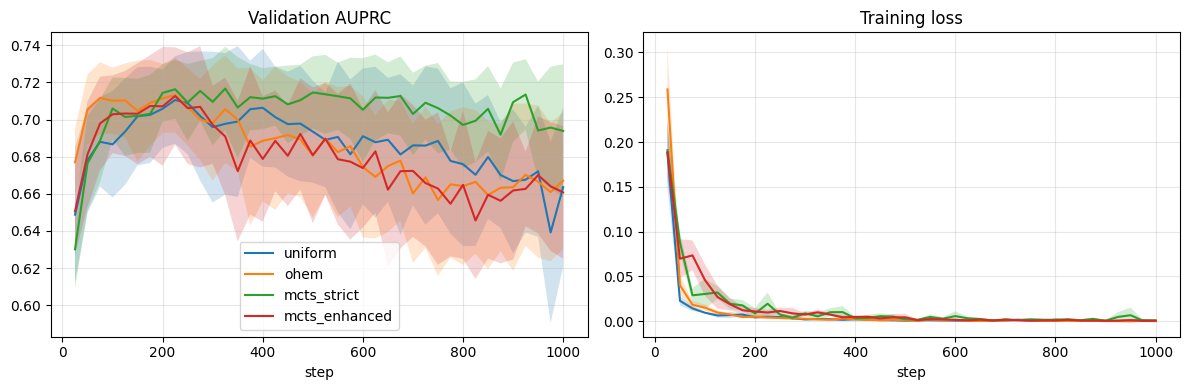

In [8]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for strat in CFG.strategies:
    hs = [r["history"] for r in recs if r["strategy"] == strat]
    if not hs:
        continue
    steps = [h["step"] for h in hs[0]]
    for ax, key in zip(axes, ("val_AUPRC", "train_loss")):
        vals = np.array([[h[key] for h in hist] for hist in hs if len(hist) == len(steps)])
        m, s = vals.mean(0), vals.std(0)
        ax.plot(steps, m, label=strat)
        ax.fill_between(steps, m - s, m + s, alpha=0.2)
for ax, t in zip(axes, ("Validation AUPRC", "Training loss")):
    ax.set_title(t); ax.set_xlabel("step"); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
fig.savefig(out / f"{CFG.campaign}_curves.png", dpi=150)
plt.show()

### Bring the results back
If Drive was mounted, the JSONs are already in `MyDrive/mcts-hnm-results/tier2/`. Otherwise they live only on
the Colab VM: the cell below prints them as a base64 zip **into this notebook's output**. Save the notebook
(Ctrl+S), then on your machine run `python -m src.training.tier2_gpu notebooks/06_tier2_gpu_campaign.ipynb`
to unpack them into `results/real/tier2/`. Only then shut the server down.

In [9]:
from src.training.tier2_gpu import print_results_zip
if str(CFG.output_dir).startswith("/content/drive"):
    print("Results are on Google Drive:", CFG.output_dir)
else:
    print_results_zip(CFG.output_dir, REPO_ROOT / f"{CFG.campaign}_results")

Results are on Google Drive: /content/drive/MyDrive/mcts-hnm-results/tier2
